# AAI640 — Assignment 4: CNN Transfer Learning

**Student:** Michael Kelly Osei  
**Dataset:** CIFAR-10  
**Models:** ResNet50 and EfficientNetB0, both with ImageNet weights and 96 × 96 input images

We will first train a small classification head while each pretrained CNN is frozen. Then we will unfreeze only its upper layers and continue training with a smaller learning rate. The validation set chooses the final model. The test set is kept aside until that choice is made.

This notebook uses a CPU-only TensorFlow environment. CNN training can take a while.

## 1. Load and prepare the data

We use the official CIFAR-10 training images to make a reproducible, stratified 45,000/5,000 training/validation split. We do not inspect the test images or labels here. They are kept for the one final evaluation.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.datasets import cifar10

SEED = 6404
IMAGE_SIZE = 96
BATCH_SIZE = 64
MAX_EPOCHS = 15
PATIENCE = 2
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
AUTOTUNE = tf.data.AUTOTUNE

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Compute devices:", tf.config.list_physical_devices())

(X_all, y_all_raw), (X_test_images, y_test_raw) = cifar10.load_data()
y_all = y_all_raw.reshape(-1).astype(np.int64)
train_idx, val_idx = train_test_split(
    np.arange(len(y_all)), test_size=5000, random_state=SEED, stratify=y_all
)
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]

print("Training image shape:", X_train.shape, "| labels:", y_train.shape)
print("Validation image shape:", X_val.shape, "| labels:", y_val.shape)
print("Classes:", len(CLASS_NAMES), CLASS_NAMES)
class_counts = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": np.bincount(y_train, minlength=10),
    "validation": np.bincount(y_val, minlength=10),
})
display(class_counts)
assert len(X_train) == 45000 and len(X_val) == 5000

TensorFlow: 2.16.2
Compute devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Training image shape: (45000, 32, 32, 3) | labels: (45000,)
Validation image shape: (5000, 32, 32, 3) | labels: (5000,)
Classes: 10 ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


,class,train,validation
0,airplane,4500,500
1,automobile,4500,500
2,bird,4500,500
3,cat,4500,500
4,deer,4500,500
5,dog,4500,500
6,frog,4500,500
7,horse,4500,500
8,ship,4500,500
9,truck,4500,500


The images are 32 × 32 RGB. We resize them to 96 × 96 inside the input pipeline, rather than storing a second resized copy. Both models receive the same image size, but each gets the preprocessing used for its ImageNet weights. This keeps the architecture comparison fair. The test arrays have only been loaded and held aside; their contents are not examined before final model selection.

## 2. Choose the architectures and preprocessing

ResNet50 uses residual connections; EfficientNetB0 uses a compact, scaled convolutional design. Both are supported by Keras and use the same ImageNet pretraining source. Their different input preprocessing is required by their pretrained weights.

In [2]:
def preprocess_image(image, label, architecture):
    image = tf.image.resize(tf.cast(image, tf.float32), [IMAGE_SIZE, IMAGE_SIZE])
    if architecture == "ResNet50":
        image = tf.keras.applications.resnet50.preprocess_input(image)
    elif architecture == "EfficientNetB0":
        image = tf.keras.applications.efficientnet.preprocess_input(image)
    return image, label


def make_dataset(images, labels, architecture, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        dataset = dataset.shuffle(len(labels), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(
        lambda image, label: preprocess_image(image, label, architecture),
        num_parallel_calls=AUTOTUNE,
    )
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


ARCHITECTURES = ["ResNet50", "EfficientNetB0"]

def load_base(architecture):
    if architecture == "ResNet50":
        base = tf.keras.applications.ResNet50(
            include_top=False, weights="imagenet", input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
        )
    else:
        base = tf.keras.applications.EfficientNetB0(
            include_top=False, weights="imagenet", input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
        )
    return base


def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )


def fit_callbacks():
    return [EarlyStopping(
        monitor="val_accuracy", mode="max", patience=PATIENCE,
        restore_best_weights=True, verbose=1,
    )]


def summarize_history(history, elapsed, model):
    values = history.history
    best = int(np.argmax(values["val_accuracy"]))
    trainable = sum(int(np.prod(weight.shape)) for weight in model.trainable_weights)
    return {
        "best_val_accuracy": float(values["val_accuracy"][best]),
        "val_loss_at_best_accuracy": float(values["val_loss"][best]),
        "best_epoch": best + 1,
        "train_accuracy_at_best_epoch": float(values["accuracy"][best]),
        "generalization_gap": float(values["accuracy"][best] - values["val_accuracy"][best]),
        "epochs_run": len(values["loss"]),
        "training_seconds": float(elapsed),
        "total_parameters": int(model.count_params()),
        "trainable_parameters": trainable,
    }

## 3. Feature extraction: train only the new head

For each model, we freeze the ImageNet CNN and train the same global-average-pooling plus 10-class softmax head. We cache only the pooled features for this stage. That is equivalent to passing every image through a frozen base each epoch, and it avoids repeating expensive CNN work. The fine-tuning stage below returns to the image input pipeline.

In [3]:
base_models = {}
transfer_models = {}
histories = {}
results = {}


def train_feature_head(architecture, seed_offset):
    tf.keras.utils.set_random_seed(SEED + seed_offset)
    base = load_base(architecture)
    base.trainable = False
    pooled = layers.GlobalAveragePooling2D()(base.output)
    extractor = models.Model(base.input, pooled, name=f"{architecture}_feature_extractor")

    train_images = make_dataset(X_train, y_train, architecture, training=False)
    val_images = make_dataset(X_val, y_val, architecture, training=False)
    start = time.perf_counter()
    train_features = extractor.predict(train_images, verbose=0)
    val_features = extractor.predict(val_images, verbose=0)

    head_input = layers.Input(shape=(train_features.shape[1],), name="pooled_features")
    head = layers.Dense(10, activation="softmax", name="class_predictions")
    head_model = models.Model(head_input, head(head_input), name=f"{architecture}_head")
    compile_model(head_model, learning_rate=0.001)
    history = head_model.fit(
        train_features, y_train,
        validation_data=(val_features, y_val),
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, shuffle=True,
        callbacks=fit_callbacks(), verbose=2,
    )

    image_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name="preprocessed_image")
    image_features = layers.GlobalAveragePooling2D()(base(image_input, training=False))
    output = head(image_features)
    full_model = models.Model(image_input, output, name=f"{architecture}_transfer_model")
    base_models[architecture] = base
    transfer_models[architecture] = full_model
    elapsed = time.perf_counter() - start
    result = summarize_history(history, elapsed, full_model)
    del train_features, val_features, extractor, head_model
    return history, result


for offset, architecture in enumerate(ARCHITECTURES):
    history, result = train_feature_head(architecture, offset)
    histories[(architecture, "Feature extraction")] = history
    results[(architecture, "Feature extraction")] = result
    print(architecture, "feature extraction:", result)

Epoch 1/15
704/704 - 1s - 1ms/step - accuracy: 0.8051 - loss: 0.6305 - val_accuracy: 0.8416 - val_loss: 0.4944
Epoch 2/15
704/704 - 0s - 675us/step - accuracy: 0.8632 - loss: 0.4223 - val_accuracy: 0.8480 - val_loss: 0.4777
Epoch 3/15
704/704 - 0s - 667us/step - accuracy: 0.8814 - loss: 0.3629 - val_accuracy: 0.8486 - val_loss: 0.4859
Epoch 4/15
704/704 - 0s - 667us/step - accuracy: 0.8915 - loss: 0.3278 - val_accuracy: 0.8510 - val_loss: 0.4996
Epoch 5/15
704/704 - 1s - 816us/step - accuracy: 0.8996 - loss: 0.3040 - val_accuracy: 0.8480 - val_loss: 0.5142
Epoch 6/15
704/704 - 0s - 675us/step - accuracy: 0.9055 - loss: 0.2865 - val_accuracy: 0.8474 - val_loss: 0.5293
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 4.
ResNet50 feature extraction: {'best_val_accuracy': 0.8510000109672546, 'val_loss_at_best_accuracy': 0.4995979368686676, 'best_epoch': 4, 'train_accuracy_at_best_epoch': 0.891511082649231, 'generalization_gap': 0.04051107168197632, 'epochs_ru

## 4. Fine-tune the upper layers

We continue from the feature-extraction weights. For each model, we unfreeze the last 20% of its base layers, but keep every BatchNormalization layer frozen. The same data split, image size, batch size, epoch limit, and stopping rule are used. The learning rate is lowered to 0.00001 so the pretrained weights change gradually.

**Log note:** Keras reports that `shuffle=True` is ignored for a `tf.data.Dataset`. The training dataset is already shuffled in `make_dataset(..., training=True)`, so this warning does not change the training order.

**Log note:** Keras reports that `shuffle=True` is ignored for a `tf.data.Dataset`. The training dataset is already shuffled in `make_dataset(..., training=True)`, so this warning does not change the training order.

In [4]:
def fine_tune(architecture):
    base = base_models[architecture]
    model = transfer_models[architecture]

    base.trainable = True
    first_unfrozen = int(len(base.layers) * 0.8)
    for index, layer in enumerate(base.layers):
        layer.trainable = index >= first_unfrozen and not isinstance(layer, layers.BatchNormalization)
    assert all(not layer.trainable for layer in base.layers if isinstance(layer, layers.BatchNormalization))

    compile_model(model, learning_rate=0.00001)
    train_images = make_dataset(X_train, y_train, architecture, training=True)
    val_images = make_dataset(X_val, y_val, architecture, training=False)
    start = time.perf_counter()
    history = model.fit(
        train_images, validation_data=val_images,
        epochs=MAX_EPOCHS, callbacks=fit_callbacks(), verbose=2,
    )
    elapsed = time.perf_counter() - start
    result = summarize_history(history, elapsed, model)
    result["unfrozen_base_layers"] = sum(layer.trainable for layer in base.layers)
    result["total_base_layers"] = len(base.layers)
    return history, result


for architecture in ARCHITECTURES:
    history, result = fine_tune(architecture)
    histories[(architecture, "Fine-tuning")] = history
    results[(architecture, "Fine-tuning")] = result
    print(architecture, "fine-tuning:", result)

Epoch 1/15


site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


704/704 - 7117s - 10s/step - accuracy: 0.9166 - loss: 0.2384 - val_accuracy: 0.8782 - val_loss: 0.3848
Epoch 2/15
704/704 - 654s - 929ms/step - accuracy: 0.9716 - loss: 0.0997 - val_accuracy: 0.8798 - val_loss: 0.4159
Epoch 3/15
704/704 - 452s - 643ms/step - accuracy: 0.9934 - loss: 0.0354 - val_accuracy: 0.8826 - val_loss: 0.4542
Epoch 4/15
704/704 - 461s - 655ms/step - accuracy: 0.9994 - loss: 0.0108 - val_accuracy: 0.8820 - val_loss: 0.5140
Epoch 5/15
704/704 - 452s - 643ms/step - accuracy: 1.0000 - loss: 0.0035 - val_accuracy: 0.8862 - val_loss: 0.5670
Epoch 6/15
704/704 - 489s - 695ms/step - accuracy: 1.0000 - loss: 0.0014 - val_accuracy: 0.8872 - val_loss: 0.6279
Epoch 7/15
704/704 - 442s - 628ms/step - accuracy: 1.0000 - loss: 6.4621e-04 - val_accuracy: 0.8846 - val_loss: 0.6703
Epoch 8/15
704/704 - 623s - 885ms/step - accuracy: 1.0000 - loss: 3.5262e-04 - val_accuracy: 0.8852 - val_loss: 0.7167
Epoch 8: early stopping
Restoring model weights from the end of the best epoch: 6.
R

**Fine-tuning layer check from the executed model setup.** ResNet50 trained 10 convolution layers in `conv5_block1`–`conv5_block3`; 151 of 175 base layers remained frozen. EfficientNetB0 trained layers in `block6c`, `block6d`, `block7a`, and `top_conv`; 200 of 238 base layers remained frozen. BatchNormalization layers stayed frozen in both models. The fine-tuning run had 14,973,962 trainable parameters for ResNet50 and 2,300,314 for EfficientNetB0, including the shared classifier head.

## 5. Compare the four runs

The table uses one reporting rule: training accuracy and the train/validation gap are measured at the epoch with the best validation accuracy. Training time includes feature extraction plus head fitting for the frozen stage, and the full fine-tuning run for the second stage.

,architecture,stage,train_accuracy_at_best_epoch,best_val_accuracy,val_loss_at_best_accuracy,generalization_gap,best_epoch,epochs_run,trainable_parameters,total_parameters,training_seconds
0,ResNet50,Feature extraction,0.8915,0.8510,0.4996,0.0405,4,6,20490,23608202,254.2596
1,EfficientNetB0,Feature extraction,0.8744,0.8598,0.4184,0.0146,3,5,12810,4062381,86.7856
2,ResNet50,Fine-tuning,1.0000,0.8872,0.6279,0.1128,6,8,14973962,23608202,3729.0603
3,EfficientNetB0,Fine-tuning,0.9226,0.8984,0.3206,0.0242,7,9,2300314,4062381,997.2640


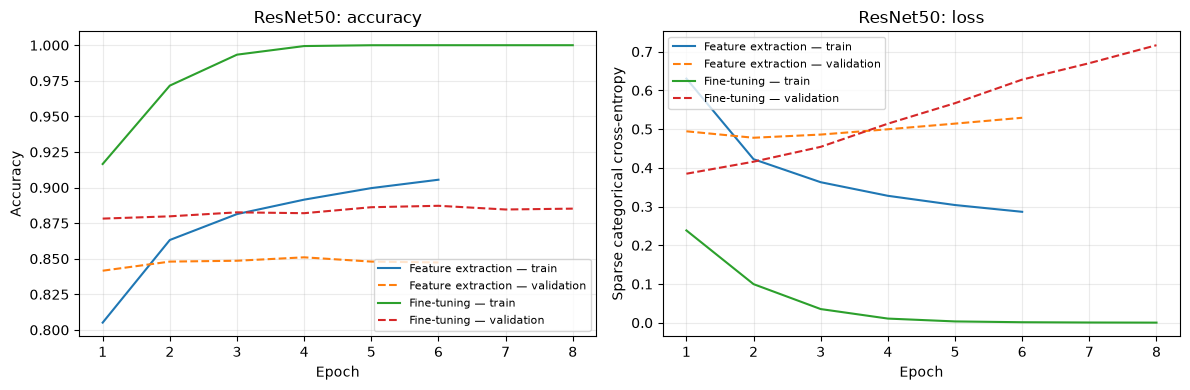

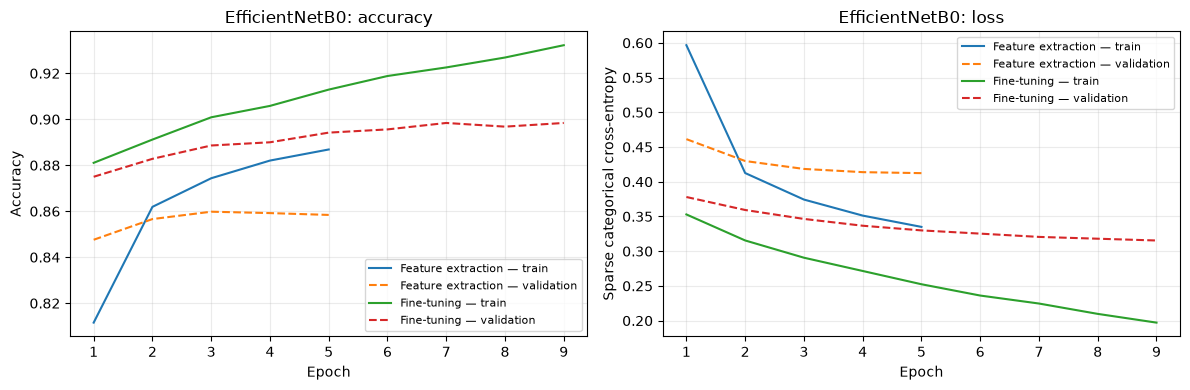

In [5]:
result_table = pd.DataFrame([
    {"architecture": architecture, "stage": stage, **metrics}
    for (architecture, stage), metrics in results.items()
])
display(result_table[[
    "architecture", "stage", "train_accuracy_at_best_epoch", "best_val_accuracy",
    "val_loss_at_best_accuracy", "generalization_gap", "best_epoch", "epochs_run",
    "trainable_parameters", "total_parameters", "training_seconds",
]].round(4))

for architecture in ARCHITECTURES:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for stage in ["Feature extraction", "Fine-tuning"]:
        history = histories[(architecture, stage)].history
        epochs = np.arange(1, len(history["accuracy"]) + 1)
        axes[0].plot(epochs, history["accuracy"], label=f"{stage} — train")
        axes[0].plot(epochs, history["val_accuracy"], linestyle="--", label=f"{stage} — validation")
        axes[1].plot(epochs, history["loss"], label=f"{stage} — train")
        axes[1].plot(epochs, history["val_loss"], linestyle="--", label=f"{stage} — validation")
    axes[0].set(title=f"{architecture}: accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[1].set(title=f"{architecture}: loss", xlabel="Epoch", ylabel="Sparse categorical cross-entropy")
    for axis in axes:
        axis.legend(fontsize=8)
        axis.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

Use the table and curves to compare what changed when layers were unfrozen. A higher training score alone is not enough: compare the validation score and the train/validation gap too. The final model is chosen using validation accuracy only; ties are broken by lower validation loss, then shorter measured training time.

## 6. Select the final model using validation data

No test scores are used in this decision. The early-stopping callback restored the best validation-accuracy weights for each run.

In [6]:
selected_key = sorted(
    results,
    key=lambda key: (
        -results[key]["best_val_accuracy"],
        results[key]["val_loss_at_best_accuracy"],
        results[key]["training_seconds"],
    ),
)[0]
selected_architecture, selected_stage = selected_key
final_model = transfer_models[selected_architecture]
selected_result = results[selected_key]
print("Selected on validation:", selected_architecture, "—", selected_stage)
print("Best validation accuracy:", round(selected_result["best_val_accuracy"], 4))
print("Best epoch:", selected_result["best_epoch"])
print("Trainable / total parameters:", selected_result["trainable_parameters"], "/", selected_result["total_parameters"])

Selected on validation: EfficientNetB0 — Fine-tuning
Best validation accuracy: 0.8984
Best epoch: 7
Trainable / total parameters: 2300314 / 4062381


## 7. One final test evaluation

Now that the model is selected, we make one prediction pass over the held-out test set. Accuracy, loss, the confusion matrix, and per-class scores are all calculated from these same predictions. We do not use test results to change the model.

Final test image shape: (10000, 32, 32, 3) | test labels: (10000,)
Final test accuracy: 0.8946
Final test loss: 0.3173
Final model: EfficientNetB0 — Fine-tuning
              precision    recall  f1-score   support

    airplane     0.9056    0.8920    0.8987      1000
  automobile     0.9377    0.9490    0.9433      1000
        bird     0.8874    0.8750    0.8812      1000
         cat     0.8045    0.7900    0.7972      1000
        deer     0.8664    0.8820    0.8741      1000
         dog     0.8466    0.8280    0.8372      1000
        frog     0.9163    0.9420    0.9290      1000
       horse     0.9226    0.9180    0.9203      1000
        ship     0.9308    0.9280    0.9294      1000
       truck     0.9244    0.9420    0.9331      1000

    accuracy                         0.8946     10000
   macro avg     0.8942    0.8946    0.8944     10000
weighted avg     0.8942    0.8946    0.8944     10000



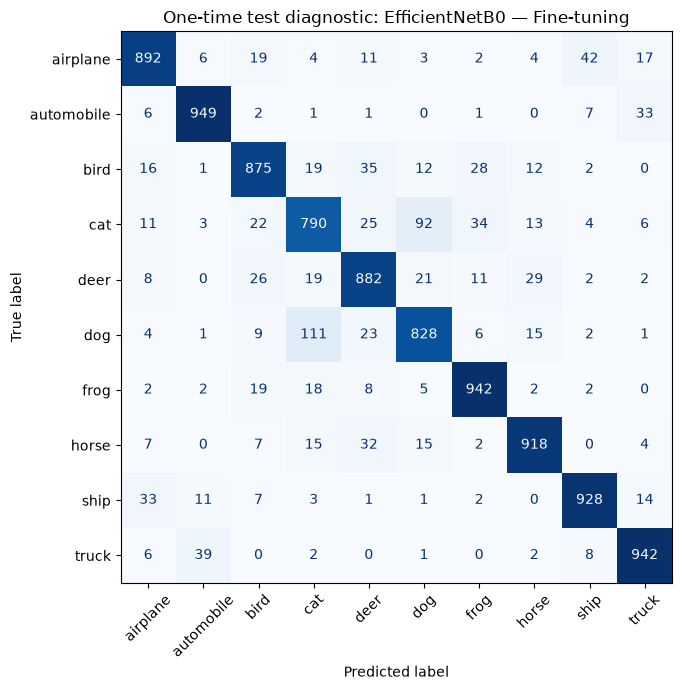

Most frequent incorrect class pair: dog predicted as cat — 111


In [7]:
y_test = y_test_raw.reshape(-1).astype(np.int64)
test_images = make_dataset(X_test_images, y_test, selected_architecture, training=False)
test_probabilities = final_model.predict(test_images, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=1)
test_accuracy = accuracy_score(y_test, test_predictions)
test_loss = float(tf.reduce_mean(
    tf.keras.losses.sparse_categorical_crossentropy(y_test, test_probabilities)
).numpy())
test_matrix = confusion_matrix(y_test, test_predictions, labels=np.arange(10))

print("Final test image shape:", X_test_images.shape, "| test labels:", y_test.shape)
print("Final test accuracy:", round(float(test_accuracy), 4))
print("Final test loss:", round(test_loss, 4))
print("Final model:", selected_architecture, "—", selected_stage)
print(classification_report(y_test, test_predictions, target_names=CLASS_NAMES, digits=4, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(test_matrix, display_labels=CLASS_NAMES).plot(
    ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues", values_format="d"
)
ax.set_title(f"One-time test diagnostic: {selected_architecture} — {selected_stage}")
plt.tight_layout()
plt.show()

confusion_without_diagonal = test_matrix.copy()
np.fill_diagonal(confusion_without_diagonal, 0)
most_confused = np.unravel_index(np.argmax(confusion_without_diagonal), confusion_without_diagonal.shape)
print("Most frequent incorrect class pair:",
      CLASS_NAMES[most_confused[0]], "predicted as", CLASS_NAMES[most_confused[1]],
      "—", int(confusion_without_diagonal[most_confused]))

**What the measured results show.** Fine-tuning raised validation accuracy by 0.0362 for ResNet50 and 0.0386 for EfficientNetB0. For ResNet50, the train/validation accuracy gap widened from 0.0405 to 0.1128 and validation loss rose from 0.4996 to 0.6279, so its higher accuracy came with a larger gap and worse loss. For EfficientNetB0, the gap changed only from 0.0146 to 0.0242 while validation loss fell from 0.4184 to 0.3206. EfficientNetB0 fine-tuning had the best validation accuracy (0.8984), fewer trainable parameters (2,300,314 versus ResNet50’s 14,973,962), fewer total parameters (4,062,381 versus 23,608,202), and shorter measured training time (656.0 versus 2,548.1 seconds). These results make it the strongest balance in this run; they do not prove that one architecture is always better.

The single test-pass diagnostic found the lowest class F1 for cat (0.7972); the most frequent error was dog predicted as cat (111 images). This shows which class pair was hardest here, but the notebook does not test why those images were confused.

**Submission reminder:** This notebook contains the code, visible outputs, plots, comparison, and final reflection. Review the results and submit the `.ipynb` file through Canvas.

In [9]:
feature_deltas = {}
for architecture in ARCHITECTURES:
    feature_score = results[(architecture, "Feature extraction")]["best_val_accuracy"]
    fine_score = results[(architecture, "Fine-tuning")]["best_val_accuracy"]
    feature_deltas[architecture] = fine_score - feature_score

best_feature = max(ARCHITECTURES, key=lambda arch: results[(arch, "Feature extraction")]["best_val_accuracy"])
best_finetuned = max(ARCHITECTURES, key=lambda arch: results[(arch, "Fine-tuning")]["best_val_accuracy"])

reflection = (
   f"**Feature extraction and fine-tuning.** I learned that feature extraction only trains the new 10-class head, while fine-tuning also allows the upper layers of the base model to learn from the data. "
f"BatchNormalization remained frozen during both stages. "
f"After fine-tuning, ResNet50 validation accuracy changed by {feature_deltas['ResNet50']:+.4f}, while EfficientNetB0 changed by {feature_deltas['EfficientNetB0']:+.4f}. "
f"Looking at the training and validation curves helps us understand whether fine-tuning actually improved performance or mainly improved training accuracy. "
f"The best feature-extraction result was {best_feature} ({results[(best_feature, 'Feature extraction')]['best_val_accuracy']:.4f}), while the best fine-tuned result was {best_finetuned} ({results[(best_finetuned, 'Fine-tuning')]['best_val_accuracy']:.4f}). "
f"We selected {selected_architecture} — {selected_stage} because it had the best validation accuracy, using validation loss and training time to break ties. "
f"It had {selected_result['trainable_parameters']:,} trainable parameters out of {selected_result['total_parameters']:,} total and took {selected_result['training_seconds']:.1f} seconds to train on the CPU. "
f"ResNet50 uses residual connections, while EfficientNetB0 uses a different design that aims to reduce computing costs. These differences may help explain the results, but we cannot say for sure that they caused the performance difference. "
f"The model achieved a test accuracy of {test_accuracy:.4f} and a test loss of {test_loss:.4f} in its one-time test."
)
display(Markdown(reflection))

**Feature extraction and fine-tuning.** I learned that feature extraction only trains the new 10-class head, while fine-tuning also allows the upper layers of the base model to learn from the data. BatchNormalization remained frozen during both stages. After fine-tuning, ResNet50 validation accuracy changed by +0.0362, while EfficientNetB0 changed by +0.0386. Looking at the training and validation curves helps us understand whether fine-tuning actually improved performance or mainly improved training accuracy. The best feature-extraction result was EfficientNetB0 (0.8598), while the best fine-tuned result was EfficientNetB0 (0.8984). We selected EfficientNetB0 — Fine-tuning because it had the best validation accuracy, using validation loss and training time to break ties. It had 2,300,314 trainable parameters out of 4,062,381 total and took 997.3 seconds to train on the CPU. ResNet50 uses residual connections, while EfficientNetB0 uses a different design that aims to reduce computing costs. These differences may help explain the results, but we cannot say for sure that they caused the performance difference. The model achieved a test accuracy of 0.8946 and a test loss of 0.3173 in its one-time test.